# Email A/B Test: Did the Emails Work?

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from ab_tools import bootstrap_diff, holm_adjust, sample_size_per_group, srm_check, two_proportion_test

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a" # control, mens email, womens email
df = pd.read_csv("../data/hillstrom.csv")
print(df.shape)
df.head()

(64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [2]:
print("Missing values:", df.isna().sum().sum())
print(df["segment"].value_counts())
df.describe().round(2)

Missing values: 0
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64


,recency,history,mens,womens,newbie,visit,conversion,spend
count,64000.00,64000.00,64000.00,64000.00,64000.0,64000.00,64000.00,64000.00
mean,5.76,242.09,0.55,0.55,0.5,0.15,0.01,1.05
std,3.51,256.16,0.50,0.50,0.5,0.35,0.09,15.04
min,1.00,29.99,0.00,0.00,0.0,0.00,0.00,0.00
25%,2.00,64.66,0.00,0.00,0.0,0.00,0.00,0.00
50%,6.00,158.11,1.00,1.00,1.0,0.00,0.00,0.00
75%,9.00,325.66,1.00,1.00,1.0,0.00,0.00,0.00
max,12.00,3345.93,1.00,1.00,1.0,1.00,1.00,499.00


In [3]:
counts = df["segment"].value_counts()
p_srm = srm_check(counts.tolist())
print(f"Sample ratio mismatch p-value: {p_srm:.3f}")
print("RED FLAG" if p_srm < 0.01 else "Split looks fine: about one-third each")

Sample ratio mismatch p-value: 0.904
Split looks fine: about one-third each


In [4]:
# Randomization check: customer features should look the same in every group
df.groupby("segment")[["recency", "history", "mens", "womens", "newbie"]].mean().round(3)

,recency,history,mens,womens,newbie
segment,,,,,
Mens E-Mail,5.774,242.836,0.551,0.551,0.502
No E-Mail,5.750,240.883,0.553,0.548,0.502
Womens E-Mail,5.768,242.537,0.549,0.550,0.503


In [5]:
for metric, baseline in [("visit", 0.106), ("conversion", 0.0057)]:
    n = sample_size_per_group(baseline, 0.01 if metric == "visit" else 0.003)
    print(f"{metric}: need {n:,} per group")

visit: need 15,487 per group
conversion: need 12,464 per group


## Data and experiment checks
The data has 64,000 customers and no missing values. The three groups are nearly equal in size (SRM p = 0.904) and look alike on recency, past spend, and product history, so randomization worked. Each group has about 21,300 customers, more than the 15,487 needed to detect a 1-point lift in visits.

In [6]:
rates = df.groupby("segment")[["visit", "conversion", "spend"]].mean()
rates.round(4)

,visit,conversion,spend
segment,,,
Mens E-Mail,0.1828,0.0125,1.4226
No E-Mail,0.1062,0.0057,0.6528
Womens E-Mail,0.1514,0.0088,1.0772


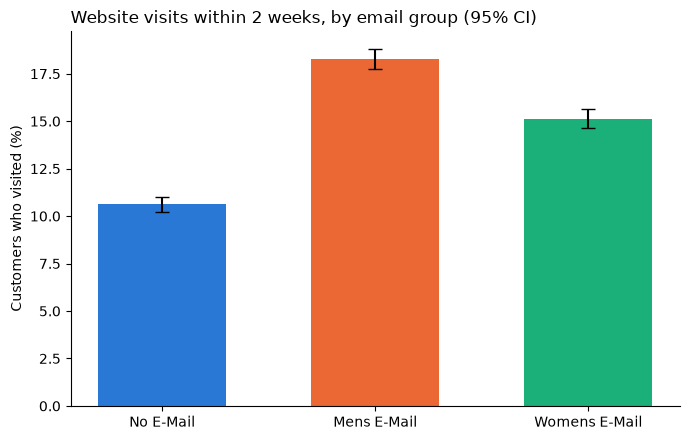

In [7]:
order = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (seg, color) in enumerate(zip(order, (BLUE, ORANGE, AQUA))):
    sub = df[df["segment"] == seg]
    p = sub["visit"].mean()
    err = 1.96 * np.sqrt(p * (1 - p) / len(sub))
    ax.bar(i, p * 100, color=color, width=0.6, yerr=err * 100, capsize=5)
ax.set_xticks(range(3), order)
ax.set_ylabel("Customers who visited (%)")
ax.set_title("Website visits within 2 weeks, by email group (95% CI)", loc="left")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/01_visit_rate_by_group.png", dpi=150)
plt.show()

In [8]:
control = df[df["segment"] == "No E-Mail"]
results = {}
for email in ["Mens E-Mail", "Womens E-Mail"]:
    grp = df[df["segment"] == email]
    for metric in ["visit", "conversion"]:
        results[f"{email} | {metric}"] = two_proportion_test(
            int(control[metric].sum()), len(control), int(grp[metric].sum()), len(grp))
table = pd.DataFrame(results).T
table["p_holm"] = holm_adjust(table["p_value"].tolist())
table.round(4)

,rate_a,rate_b,diff,z,p_value,ci_low,ci_high,p_holm
Mens E-Mail | visit,0.1062,0.1828,0.0766,22.4860,0.0000,0.0700,0.0832,0.0000
Mens E-Mail | conversion,0.0057,0.0125,0.0068,7.3851,0.0000,0.0050,0.0086,0.0000
Womens E-Mail | visit,0.1062,0.1514,0.0452,13.9492,0.0000,0.0389,0.0516,0.0000
Womens E-Mail | conversion,0.0057,0.0088,0.0031,3.7796,0.0002,0.0015,0.0047,0.0002


In [9]:
for email in ["Mens E-Mail", "Womens E-Mail"]:
    diffs = bootstrap_diff(control["spend"], df.loc[df["segment"] == email, "spend"])
    low, high = np.percentile(diffs, [2.5, 97.5])
    print(f"{email}: extra spend per customer ${diffs.mean():.2f} (95% interval ${low:.2f} to ${high:.2f})")

Mens E-Mail: extra spend per customer $0.77 (95% interval $0.48 to $1.05)
Womens E-Mail: extra spend per customer $0.42 (95% interval $0.15 to $0.69)


## Results
Both emails increased website visits compared with no email. The men's email lifted visits by 7.7 points (95% CI 7.0 to 8.3) and the women's email by 4.5 points (95% CI 3.9 to 5.2), both p < 0.0001 after Holm correction. Both emails also raised conversions, and the men's email was stronger on every measure. Extra spend per customer: men's $[YOUR RESULT], women's $[YOUR RESULT].

In [10]:
rates = df.groupby("segment")[["visit", "conversion", "spend"]].mean()
rates.round(4)

,visit,conversion,spend
segment,,,
Mens E-Mail,0.1828,0.0125,1.4226
No E-Mail,0.1062,0.0057,0.6528
Womens E-Mail,0.1514,0.0088,1.0772


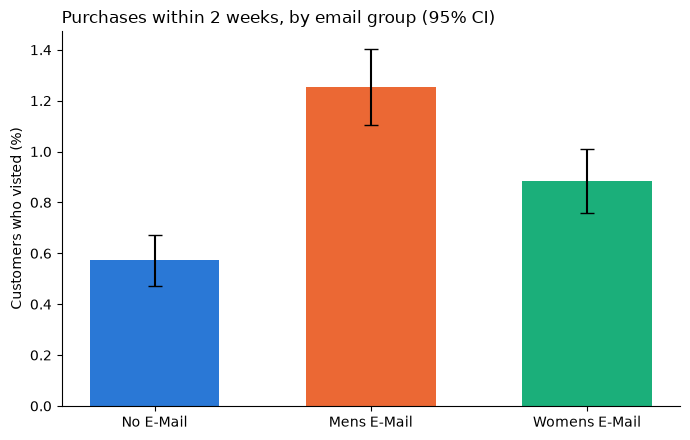

In [11]:
order = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (seg, color) in enumerate(zip(order, (BLUE, ORANGE, AQUA))):
    sub = df[df["segment"] == seg]
    p = sub["conversion"].mean()
    err = 1.96 * np.sqrt(p * (1 - p) / len(sub))
    ax.bar(i, p * 100, color=color, width=0.6, yerr=err * 100, capsize=5)
ax.set_xticks(range(3), order)
ax.set_ylabel("Customers who visted (%)")
ax.set_title("Purchases within 2 weeks, by email group (95% CI)", loc="left")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/01_conversion_rate_by_group.png", dpi=150)
plt.show()

In [12]:
control = df[df["segment"] == "No E-Mail"]
results = {}
for email in ["Mens E-Mail", "Womens E-Mail"]:
    grp = df[df["segment"] == email]
    for metric in ["visit", "conversion"]:
        results[f"{email} | {metric}"] = two_proportion_test(
            int(control[metric].sum()), len(control), int(grp[metric].sum()), len(grp))
table = pd.DataFrame(results).T
table["p_holm"] = holm_adjust(table["p_value"].tolist())
table.round(4)

,rate_a,rate_b,diff,z,p_value,ci_low,ci_high,p_holm
Mens E-Mail | visit,0.1062,0.1828,0.0766,22.4860,0.0000,0.0700,0.0832,0.0000
Mens E-Mail | conversion,0.0057,0.0125,0.0068,7.3851,0.0000,0.0050,0.0086,0.0000
Womens E-Mail | visit,0.1062,0.1514,0.0452,13.9492,0.0000,0.0389,0.0516,0.0000
Womens E-Mail | conversion,0.0057,0.0088,0.0031,3.7796,0.0002,0.0015,0.0047,0.0002


In [13]:
for email in ["Mens E-Mail", "Womens E-Mail"]:
    diffs = bootstrap_diff(control["spend"], df.loc[df["segment"] == email, "spend"])
    low, high = np.percentile(diffs, [2.5, 97.5])
    print(f"{email}: extra spend per customer ${diffs.mean():.2f} (95% interval ${low:.2f} to ${high:.2f})")

Mens E-Mail: extra spend per customer $0.77 (95% interval $0.48 to $1.05)
Womens E-Mail: extra spend per customer $0.42 (95% interval $0.15 to $0.69)


## Results
Both emails increased website visits compared with no email. The men's email lifted visits by 7.7 points (95% CI 7.0 to 8.3) and the women's email by 4.5 points (95% CI 3.9 to 5.2), both p < 0.0001 after Holm correction. Both emails also raised conversions, and the men's email was stronger on every measure. Extra spend per customer: men's $0.77, women's $0.42.